# Task 3: Feature Engineering

### Imports

In [84]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, RidgeCV, MultiTaskLassoCV
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils import resample
from skl2onnx import convert_sklearn
from skl2onnx.common.data_types import FloatTensorType
import seaborn as sns
from sklearn.neighbors import KNeighborsRegressor

### Auxiliary functions

In [85]:
# got this code from https://stackoverflow.com/questions/17315737/split-a-large-pandas-dataframe or https://www.statology.org/pandas-chunk-dataframe/
def fixed_size_subframes(data):
    n = 257
    return [data[i : i + n].copy() for i in range(0, data.shape[0], n)]


def remove_useless_rows(subframes):
    cleaned_subframes = []
    
    for df in subframes:
        # Identify rows where all values except for 'Id' are 0
        mask = (df.drop(columns=['Id']) != 0).any(axis=1)
        
        # Filter out the "useless" rows
        cleaned_df = df[mask]
        
        # Append the cleaned dataframe to the list
        if not cleaned_df.empty:
            cleaned_subframes.append(cleaned_df)
    
    return cleaned_subframes


def augment_dataset(df, features_to_drop=[], enable_euclidian_dist=False, enable_angles=False, enable_polars=False):
    # Calculate Euclidean distances between points (x_1, y_1), (x_2, y_2), and (x_3, y_3)
    if enable_euclidian_dist:
        df['dist_12'] = np.sqrt((df['x_2'] - df['x_1'])**2 + (df['y_2'] - df['y_1'])**2)
        df['dist_23'] = np.sqrt((df['x_3'] - df['x_2'])**2 + (df['y_3'] - df['y_2'])**2)
        df['dist_13'] = np.sqrt((df['x_3'] - df['x_1'])**2 + (df['y_3'] - df['y_1'])**2)

    # Calculate the angles between the points
    if enable_angles:
        df['angle_1'] = calculate_angle(df['x_1'], df['y_1'], df['x_2'], df['y_2'], df['x_3'], df['y_3'])
        df['angle_2'] = calculate_angle(df['x_2'], df['y_2'], df['x_1'], df['y_1'], df['x_3'], df['y_3'])
        df['angle_3'] = calculate_angle(df['x_3'], df['y_3'], df['x_1'], df['y_1'], df['x_2'], df['y_2'])

    # Calculate polar coordinates for each point
    if enable_polars:
        df['r_1'], df['theta_1'] = calculate_polar_coordinates(df['x_1'], df['y_1'])
        df['r_2'], df['theta_2'] = calculate_polar_coordinates(df['x_2'], df['y_2'])
        df['r_3'], df['theta_3'] = calculate_polar_coordinates(df['x_3'], df['y_3'])

    return df.drop(columns=features_to_drop)


def create_features_and_targets(subframes, features_to_drop=[], enable_euclidian_dist=False, enable_angles=False, enable_polars=False):
    feature_labels = ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']
    target_labels = ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']
    X_chunks = []
    y_chunks = []
    
    for df in subframes:        
        # Get initial conditions as numpy array
        initial_conditions = df.iloc[0][feature_labels].values
        
        # Use vectorized operations to create features
        time_values = df['t'].values
        initial_conditions_repeated = np.tile(initial_conditions, (len(df), 1))  # Repeat initial conditions for all rows
        X_chunk = np.column_stack((time_values, initial_conditions_repeated))  # Combine time with initial conditions
        
        # Convert to DataFrame
        X_chunk_df = pd.DataFrame(X_chunk, columns=['t'] + feature_labels)
        X_chunk_df = augment_dataset(X_chunk_df, features_to_drop, enable_euclidian_dist, enable_angles, enable_polars)
        
        # Extract targets using vectorized operations
        y_chunk_df = df[target_labels].copy()  # Directly slice the target columns from the dataframe
        y_chunk_df = augment_dataset(y_chunk_df, [], enable_euclidian_dist, enable_angles, enable_polars)
        
        # Append the dataframes for each scenario to the chunks list
        X_chunks.append(X_chunk_df)
        y_chunks.append(y_chunk_df)
    
    return X_chunks, y_chunks


def plot_y_yhat(y_test, y_pred, plot_title = "plot"):
    labels = ['x_1','y_1','x_2','y_2','x_3','y_3']
    MAX = 500
    if len(y_test) > MAX:
        idx = np.random.choice(len(y_test),MAX, replace=False)
    else:
        idx = np.arange(len(y_test))
    plt.figure(figsize=(10,10))
    for i in range(6):
        x0 = np.min(y_test[idx,i])
        x1 = np.max(y_test[idx,i])
        plt.subplot(3,2,i+1)
        plt.scatter(y_test[idx,i],y_pred[idx,i])
        plt.xlabel('True '+labels[i])
        plt.ylabel('Predicted '+labels[i])
        plt.plot([x0,x1],[x0,x1],color='red')
        plt.axis('square')
    plt.savefig(plot_title+'.pdf')
    plt.show()


def validate_poly_regression(X_train, y_train, X_val, y_val, regressor=None, degrees=range(1, 9), max_features=None):
    best_rmse = np.inf
    best_model = None
    best_degree = None

    for degree in degrees:
        poly = PolynomialFeatures(degree, include_bias=False)
        
        # Default to Linear Regression if no regressor is specified
        if regressor is None:
            polyreg = make_pipeline(StandardScaler(), poly, LinearRegression())
        else:
            polyreg = make_pipeline(StandardScaler(), poly, regressor)
            
        polyreg.fit(X_train, y_train)
        
        n_features = poly.n_output_features_
        
        # Abort if number of features exceeds the limit
        if max_features is not None and n_features > max_features:
            break
            
        y_pred = polyreg.predict(X_val)
        
        rmse = root_mean_squared_error(y_val, y_pred)
        
        print(f"Degree {degree}: {n_features} features | RMSE: {rmse}")
        
        if rmse < best_rmse:
            best_rmse = rmse
            best_model = polyreg
            best_degree = degree
            
    print(f"Best Degree: {best_degree}, RMSE: {best_rmse}")
    
    return best_model, best_degree, best_rmse


def degree_distribution_histogram(X_train, y_train, X_val, y_val, regressor=None, degrees=range(1, 9)):
    degree_counts = {degree: 0 for degree in degrees}

    for run in range(10):
        X_train_sample, y_train_sample = resample(X_train, y_train, n_samples=int(0.01 * len(X_train)))
        _, degree, _ = validate_poly_regression(X_train_sample, y_train_sample, X_val, y_val, regressor=regressor, degrees=degrees)
        degree_counts[degree] += 1
    
    plt.bar(degree_counts.keys(), degree_counts.values())
    plt.xlabel('Polynomial Degree')
    plt.ylabel('Frequency of Selection')
    plt.title('Distribution of Best Polynomial Degree over Multiple Runs')
    plt.show()


def save_predictions(predictions, path, columns=['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']):
    df = pd.DataFrame(predictions, columns=columns)
    df_positions = df[['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']]
    df_positions['Id'] = df_positions.index
    df_positions = df_positions[['Id', 'x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']]
    df_positions.to_csv(path, index=False)
    
    
def save_model(model, name, input_df):
    print(type(model))
    initial_type = [('float_input', FloatTensorType([None, input_df.shape[1]]))]  
    # Convert the model to ONNX format
    onnx_model = convert_sklearn(model, initial_types=initial_type)
    # Save the ONNX model to a file
    with open(name, "wb") as f:
        f.write(onnx_model.SerializeToString())
        
        
def calculate_angle(x1, y1, x2, y2, x3, y3):
    # Vector from (x1, y1) to (x2, y2)
    v1_x = x2 - x1
    v1_y = y2 - y1
    
    # Vector from (x1, y1) to (x3, y3)
    v2_x = x3 - x1
    v2_y = y3 - y1
    
    # Dot product between v1 and v2
    dot_product = v1_x * v2_x + v1_y * v2_y
    
    # Magnitude of v1 and v2
    magnitude_v1 = np.sqrt(v1_x**2 + v1_y**2)
    magnitude_v2 = np.sqrt(v2_x**2 + v2_y**2)
    
    # Compute the cosine of the angle (avoid division by zero)
    cos_theta = dot_product / (magnitude_v1 * magnitude_v2 + 1e-10)
    
    # Return the angle in radians using arccos
    return np.arccos(np.clip(cos_theta, -1, 1))  # Clipping to avoid floating point precision issues


def calculate_polar_coordinates(x, y):
    # Calculate the radius (r) and angle (theta) in polar coordinates
    r = np.sqrt(x**2 + y**2)
    theta = np.arctan2(y, x)  # Use arctan2 to get the correct angle in all quadrants
    return r, theta

### Load the dataset (without velocities)

In [86]:
df = pd.read_csv('../mlNOVA/X_train.csv')
df.drop(columns=['v_x_1','v_y_1','v_x_2','v_y_2','v_x_3','v_y_3'], inplace=True) # Velocities don't seem to help
df.head()

,t,x_1,y_1,x_2,y_2,x_3,y_3,Id
0,0.000000,1.000000,0.000000,-0.266467,0.859196,-0.733533,-0.859196,0
1,0.039062,0.999548,0.000092,-0.266261,0.858781,-0.733287,-0.858874,1
2,0.078125,0.998190,0.000370,-0.265641,0.857535,-0.732549,-0.857905,2
3,0.117188,0.995925,0.000833,-0.264606,0.855456,-0.731318,-0.856289,3
4,0.156250,0.992747,0.001483,-0.263154,0.852540,-0.729592,-0.854022,4


Split dataset into list of simulations and discard null rows

In [87]:
subframes = fixed_size_subframes(df)
subframes = remove_useless_rows(subframes)

## Task 3.1 Removing variables



### Analyse feature and target correlations

Explore the features and target, and verify if there are any linear relationships between them. 

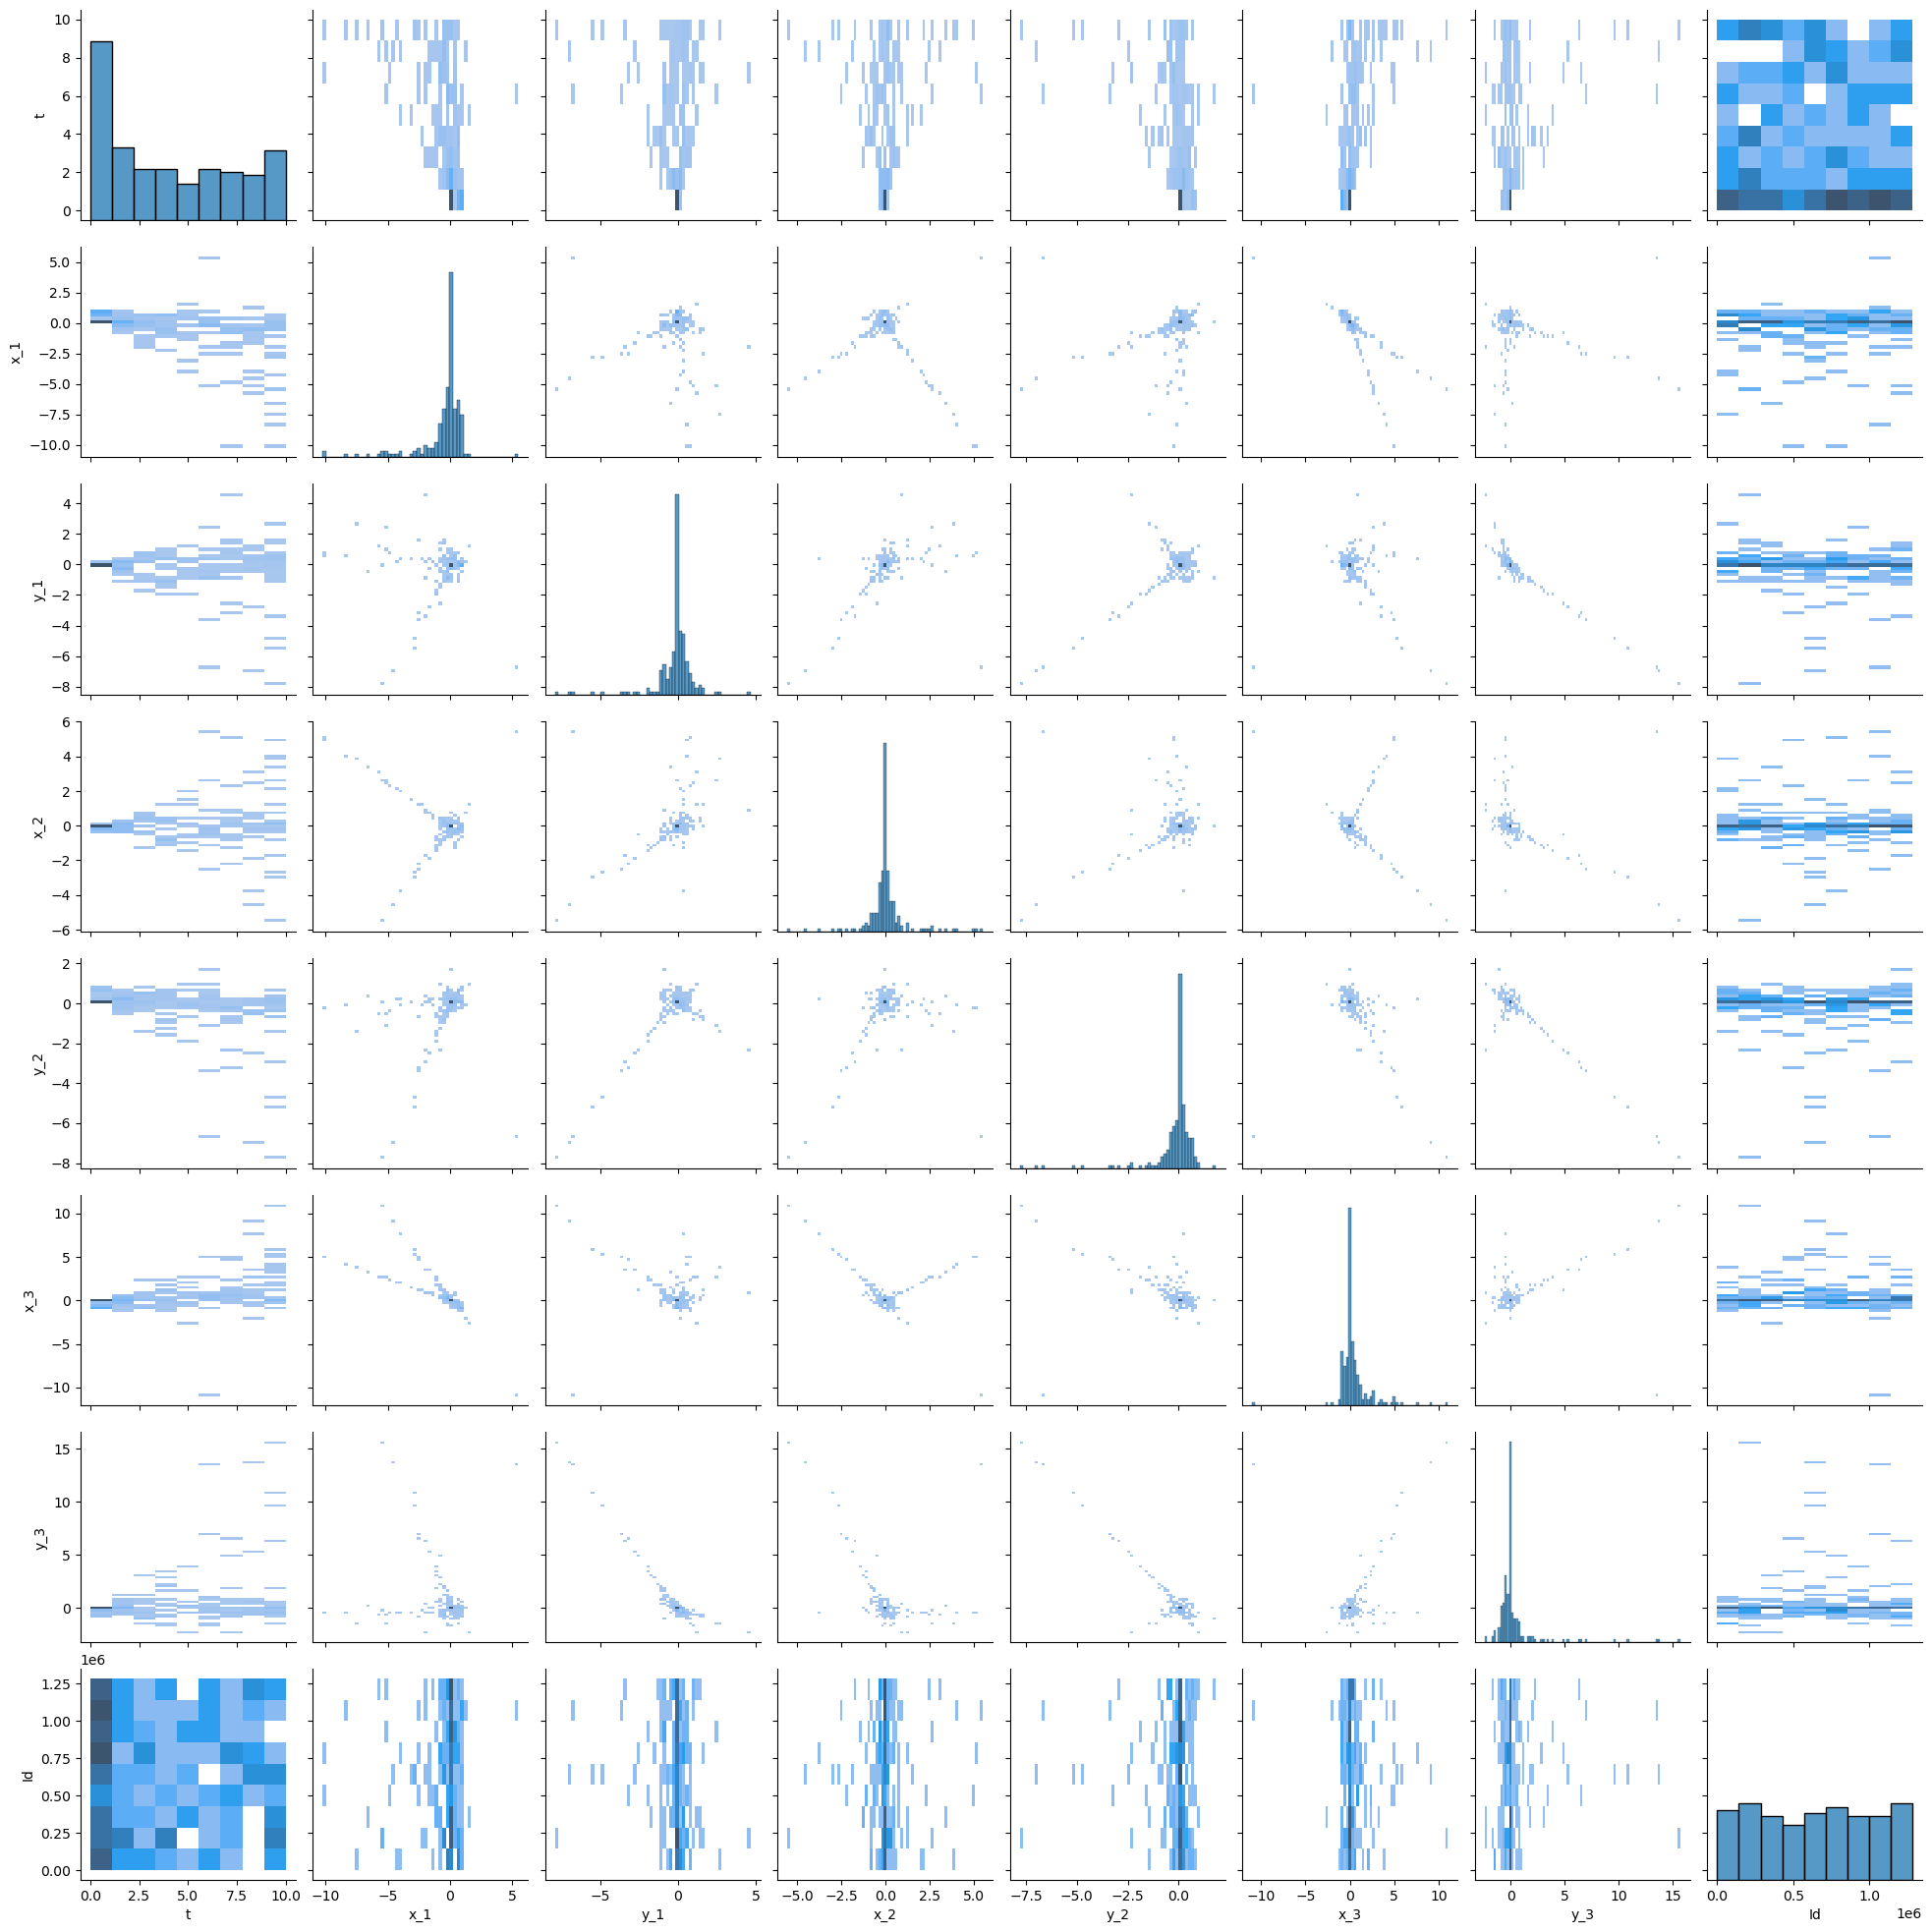

In [88]:
sns.pairplot(df.sample(200), kind="hist")

Heatmap with without velocities

<Axes: >

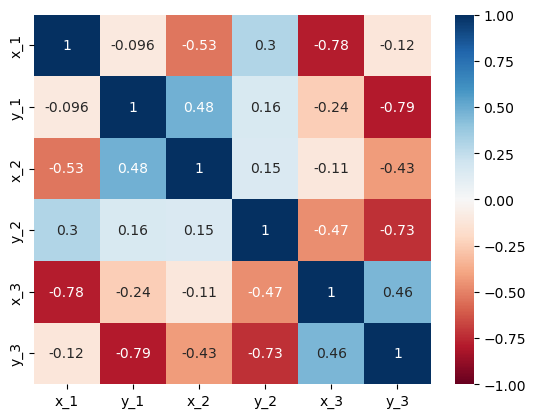

In [62]:
df_no_id_t = df.drop(columns=['t','Id'])
corr = df_no_id_t.corr()
sns.heatmap(corr, annot=True, cmap='RdBu', vmin = -1, vmax = 1)

Heatmap WITH velocities

<Axes: >

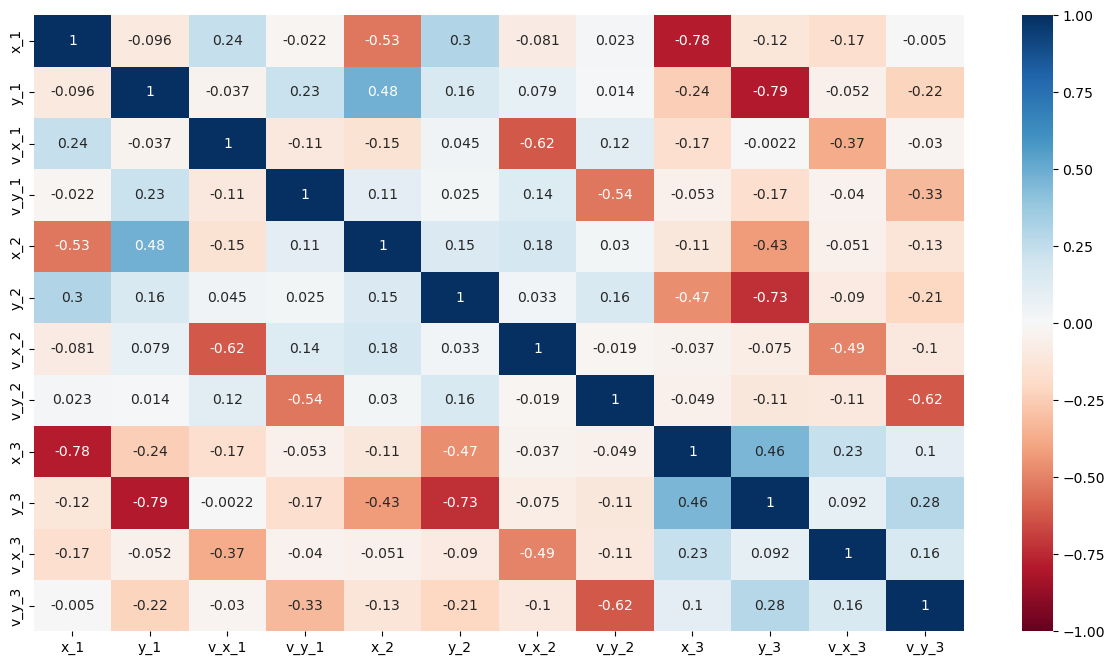

In [63]:
df_with_v = pd.read_csv('../mlNOVA/X_train.csv')
df_v_no_id_t = df_with_v.drop(columns=['t','Id'])
corr = df_v_no_id_t.corr()

plt.figure(figsize=(15,8))
sns.heatmap(corr, annot=True, cmap='RdBu', vmin = -1, vmax = 1)

### Eliminating y_3 as feature - Baseline Model

Dropping y_3

In [89]:
X_chunks, y_chunks = create_features_and_targets(subframes, features_to_drop=['y_3'])

X_train, X_dev, y_train, y_dev = train_test_split(X_chunks, y_chunks, test_size=0.2, random_state=42)
X_dev, X_test, y_dev, y_test = train_test_split(X_dev, y_dev, test_size=0.5, random_state=42)

X_train = pd.concat(X_train, axis=0)
y_train = pd.concat(y_train, axis=0)
X_dev = pd.concat(X_dev, axis=0)
y_dev = pd.concat(y_dev, axis=0)
X_test = pd.concat(X_test, axis=0)
y_test = pd.concat(y_test, axis=0)

Testing the baseline model without y_3

In [90]:
linear_reg=make_pipeline(StandardScaler(),
                      LinearRegression())

linear_reg.fit(X_train, y_train)

y_dev_pred = linear_reg.predict(X_dev)

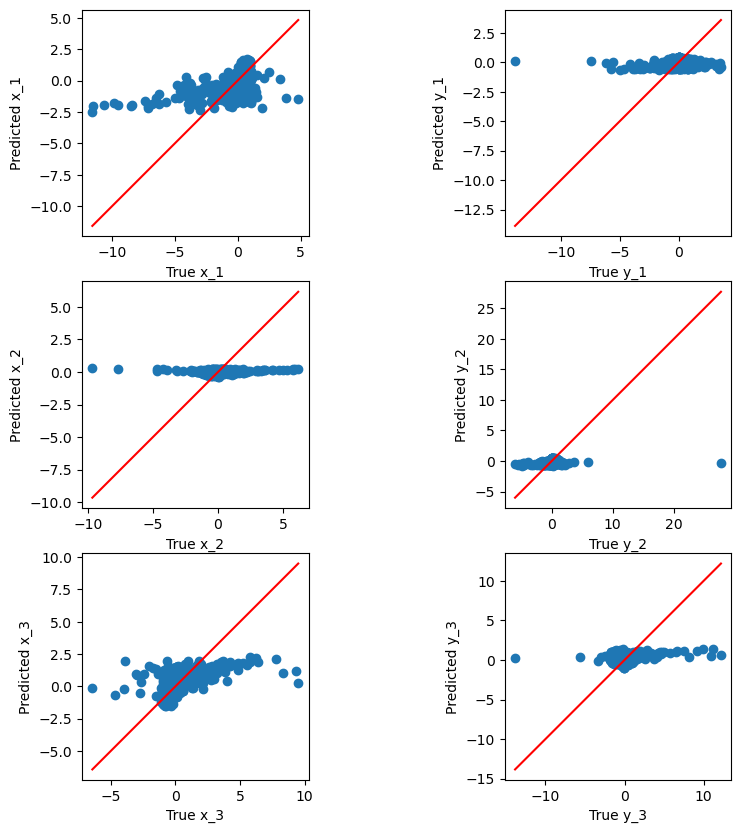

Validation RMSE: 1.3766259554905398


In [91]:
plot_y_yhat(y_dev.values, y_dev_pred, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_dev, y_dev_pred)

print(f"Validation RMSE: {rmse}")

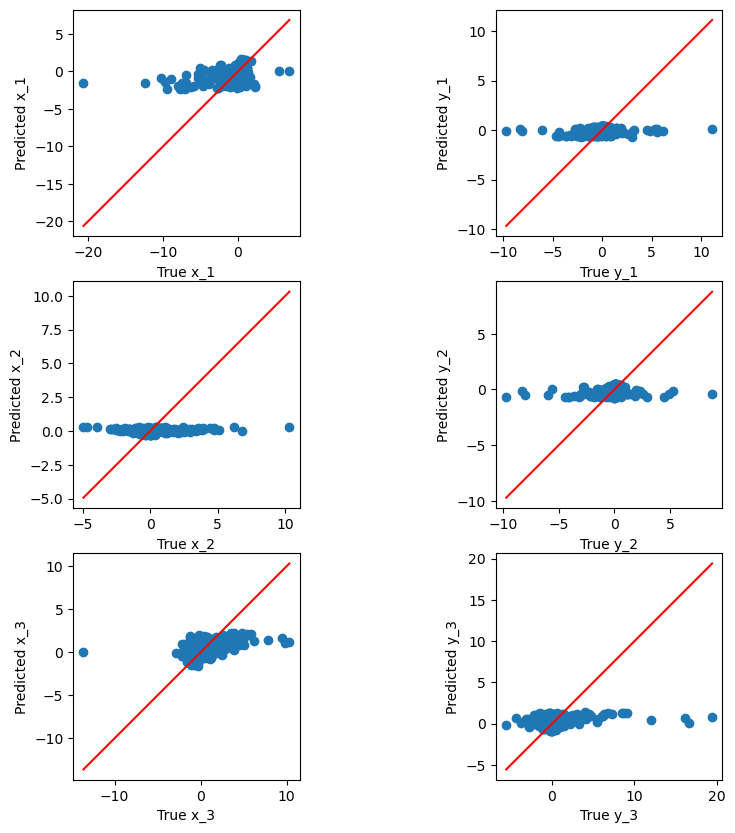

Test RMSE: 1.4524759976228878


In [92]:
y_test_pred = linear_reg.predict(X_test)

plot_y_yhat(y_test.values, y_test_pred, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_test, y_test_pred)

print(f"Test RMSE: {rmse}")

### Eliminating x_1 as feature - Baseline Model
Alongside y_3

In [93]:
X_chunks, y_chunks = create_features_and_targets(subframes, features_to_drop=['x_1', 'y_3'])

X_train, X_dev, y_train, y_dev = train_test_split(X_chunks, y_chunks, test_size=0.2, random_state=42)
X_dev, X_test, y_dev, y_test = train_test_split(X_dev, y_dev, test_size=0.5, random_state=42)

X_train = pd.concat(X_train, axis=0)
y_train = pd.concat(y_train, axis=0)
X_dev = pd.concat(X_dev, axis=0)
y_dev = pd.concat(y_dev, axis=0)
X_test = pd.concat(X_test, axis=0)
y_test = pd.concat(y_test, axis=0)

In [94]:
linear_reg=make_pipeline(StandardScaler(),
                      LinearRegression())

linear_reg.fit(X_train, y_train)

y_dev_pred = linear_reg.predict(X_dev)

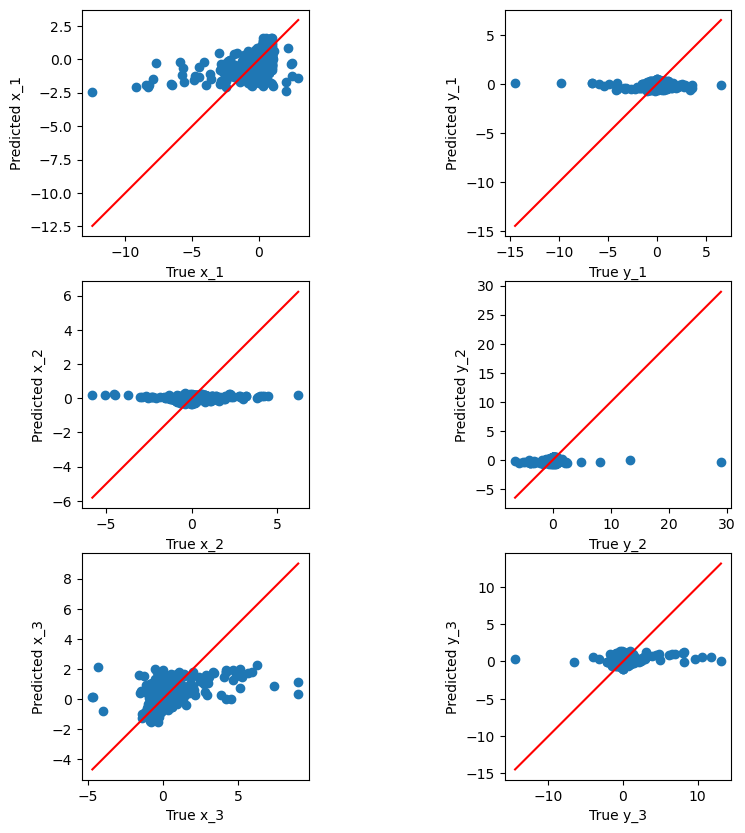

Validation RMSE: 1.3766261446822874


In [95]:
plot_y_yhat(y_dev.values, y_dev_pred, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_dev, y_dev_pred)

print(f"Validation RMSE: {rmse}")

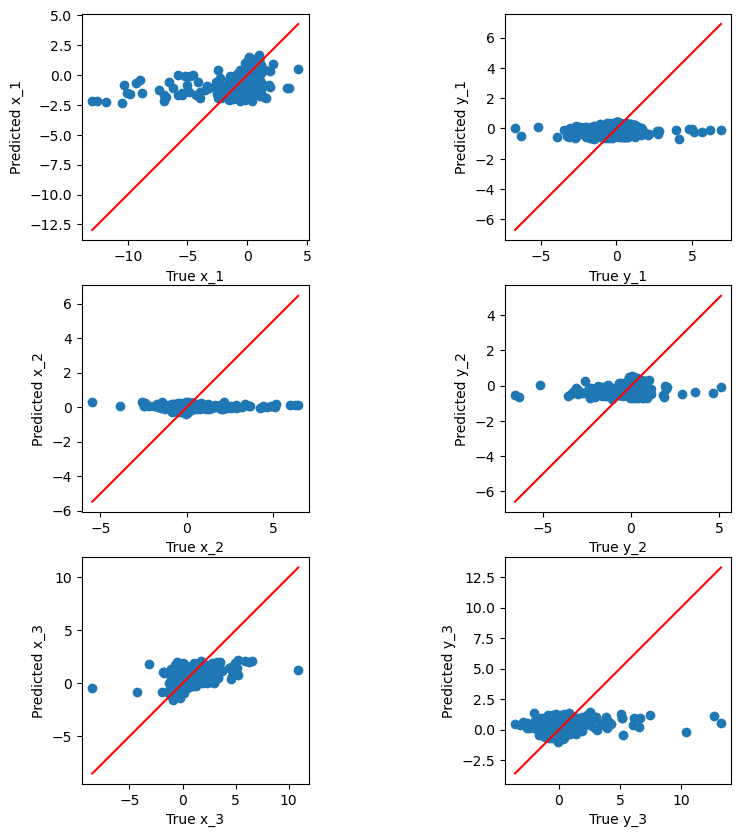

Test RMSE: 1.452475933574193


In [96]:
y_test_pred = linear_reg.predict(X_test)

plot_y_yhat(y_test.values, y_test_pred, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_test, y_test_pred)

print(f"Test RMSE: {rmse}")

## Task 3.2 Evaluation of Variable Reduction

#### Histogram of degree selection on set without y_3 and x_1

Regressor: Linear regression

In [ ]:
degree_distribution_histogram(X_train, y_train, X_dev, y_dev, regressor=LinearRegression(), degrees=range(1,10))

Ridge CV

Degree 1: 5 features | RMSE: 1.377762314677043
Degree 2: 20 features | RMSE: 1.3535363733716197
Degree 3: 55 features | RMSE: 1.3166682464520854
Degree 4: 125 features | RMSE: 1.283270697143953
Degree 5: 251 features | RMSE: 1.2666155445155265
Degree 6: 461 features | RMSE: 1.2466551159032448
Degree 7: 791 features | RMSE: 1.2257029865432167
Degree 8: 1286 features | RMSE: 1.2157433884383897
Degree 9: 2001 features | RMSE: 1.2152284820879151
Best Degree: 9, RMSE: 1.2152284820879151
Degree 1: 5 features | RMSE: 1.378080153853828
Degree 2: 20 features | RMSE: 1.3540618112538982
Degree 3: 55 features | RMSE: 1.3164812098688634
Degree 4: 125 features | RMSE: 1.2802293746531153
Degree 5: 251 features | RMSE: 1.2636013906161527
Degree 6: 461 features | RMSE: 1.2449431180371968
Degree 7: 791 features | RMSE: 1.2262488846212842
Degree 8: 1286 features | RMSE: 1.2219663029611925
Degree 9: 2001 features | RMSE: 1.221160839941553
Best Degree: 9, RMSE: 1.221160839941553
Degree 1: 5 features | RMSE

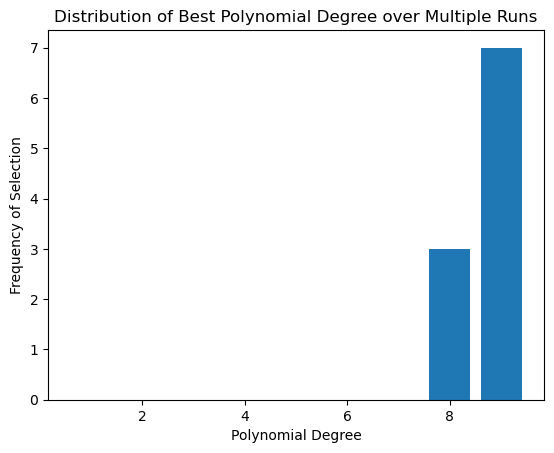

In [97]:
degree_distribution_histogram(X_train, y_train, X_dev, y_dev, regressor=RidgeCV(), degrees=range(1,10))

#### Reduced polynomial is Ridge regularization on 9th degree polynomial features 

Fitting the model

In [98]:
degree = 9

reduced_polyreg=make_pipeline(StandardScaler(), PolynomialFeatures(degree, include_bias=False),
                      RidgeCV())

# Fit the model
reduced_polyreg.fit(X_train, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('polynomialfeatures',
                 PolynomialFeatures(degree=9, include_bias=False)),
                ('ridgecv', RidgeCV())])

Validation y-y hat plot and RMSE

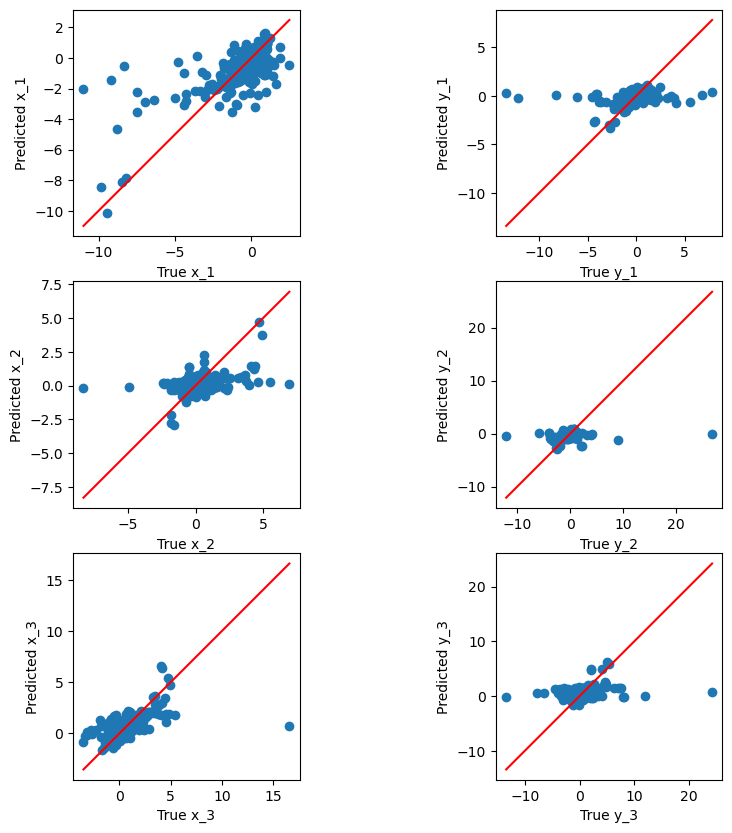

Validation RMSE: 1.1947012723593315


In [99]:
y_dev_pred = reduced_polyreg.predict(X_dev)

plot_y_yhat(y_dev.values, y_dev_pred, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_dev, y_dev_pred)

print(f"Validation RMSE: {rmse}")

Test y-y hat plot and RMSE

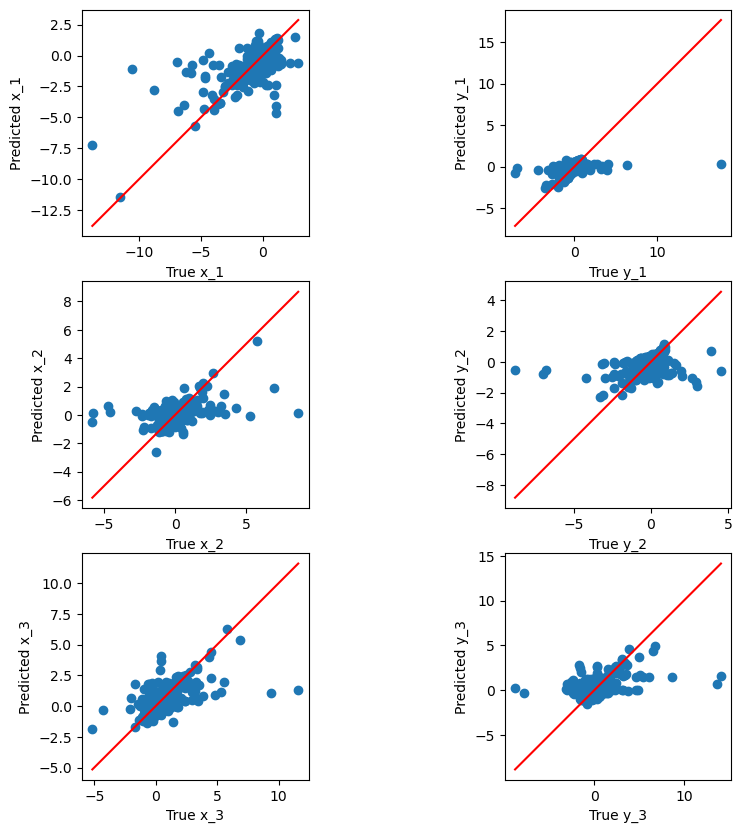

Test RMSE: 1.250186092171629


In [100]:
y_test_pred = reduced_polyreg.predict(X_test)

plot_y_yhat(y_test.values, y_test_pred, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_test, y_test_pred)

print(f"Test RMSE: {rmse}")

Save prediction

In [101]:
X_kaggle_df = pd.read_csv('../mlNOVA/X_test.csv')
X_kaggle_df.drop(columns=['Id'], inplace=True)

X_kaggle_df_No_Y_3_X_1 = X_kaggle_df.drop(columns=['x_1', 'y_3'])
X_kaggle_df_No_Y_3_X_1.head()

,t,y_1,x_2,y_2,x_3
0,0.000000,0.0,-0.179617,0.730085,-0.820383
1,0.039062,0.0,-0.179617,0.730085,-0.820383
2,0.078125,0.0,-0.179617,0.730085,-0.820383
3,0.117188,0.0,-0.179617,0.730085,-0.820383
4,0.156250,0.0,-0.179617,0.730085,-0.820383


In [102]:
y_reduced_polynomial_pred = reduced_polyreg.predict(X_kaggle_df_No_Y_3_X_1)

save_predictions(y_reduced_polynomial_pred, '../submissions/reduced_polynomial_submission.csv')

Save model

In [103]:
save_model(reduced_polyreg, "reduced_polynomial_model.onnx", X_kaggle_df_No_Y_3_X_1)

<class 'sklearn.pipeline.Pipeline'>


## Task 3.3 Adding Variables

### Adding euclidian distance between each pair of points

Pre-processing the data

In [104]:
X_chunks, y_chunks = create_features_and_targets(subframes, enable_euclidian_dist=True)

In [105]:
X_train, X_dev, y_train, y_dev = train_test_split(X_chunks, y_chunks, test_size=0.2, random_state=42)
X_dev, X_test, y_dev, y_test = train_test_split(X_dev, y_dev, test_size=0.5, random_state=42)

# Concatenate the list of DataFrames into single DataFrames for X and y
X_train = pd.concat(X_train, axis=0)
y_train = pd.concat(y_train, axis=0)
X_dev = pd.concat(X_dev, axis=0)
y_dev = pd.concat(y_dev, axis=0)
X_test = pd.concat(X_test, axis=0)
y_test = pd.concat(y_test, axis=0)

Trying it out on the baseline

In [106]:
linear_reg=make_pipeline(StandardScaler(),
                      LinearRegression())

linear_reg.fit(X_train, y_train)

y_dev_pred = linear_reg.predict(X_dev)

In [107]:
position_columns = ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']

y_dev_positions = y_dev[position_columns].values
y_pred_positions = y_dev_pred[:, range(6)]
y_test_positions = y_test[position_columns].values

Plot y-y hat and RMSE on validation set

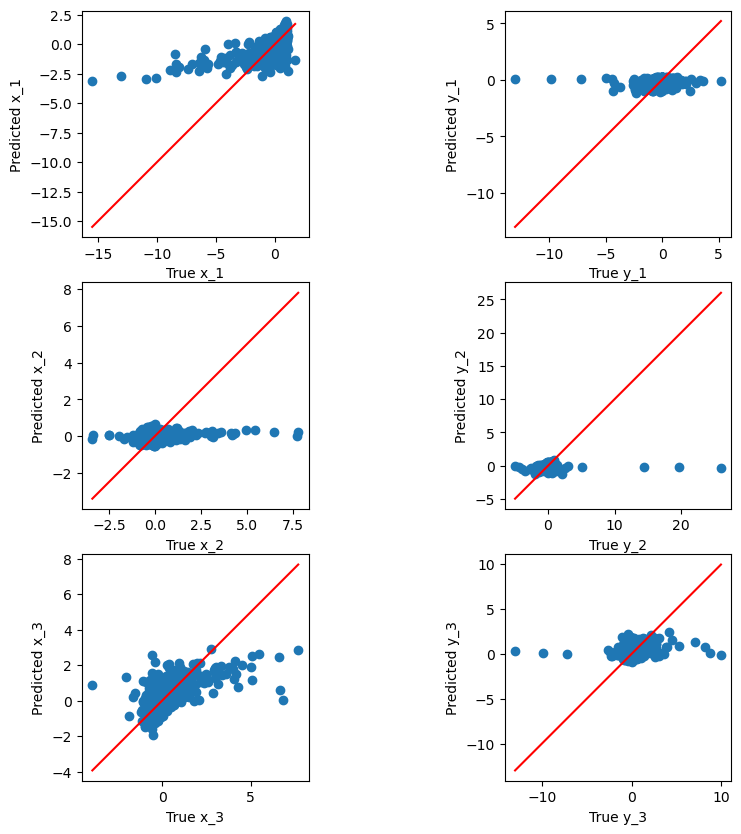

Validation RMSE: 1.354336181178171


In [108]:
plot_y_yhat(y_dev_positions, y_pred_positions, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_dev_positions, y_pred_positions)

print(f"Validation RMSE: {rmse}")

Plot y-y hat and RMSE on the test set

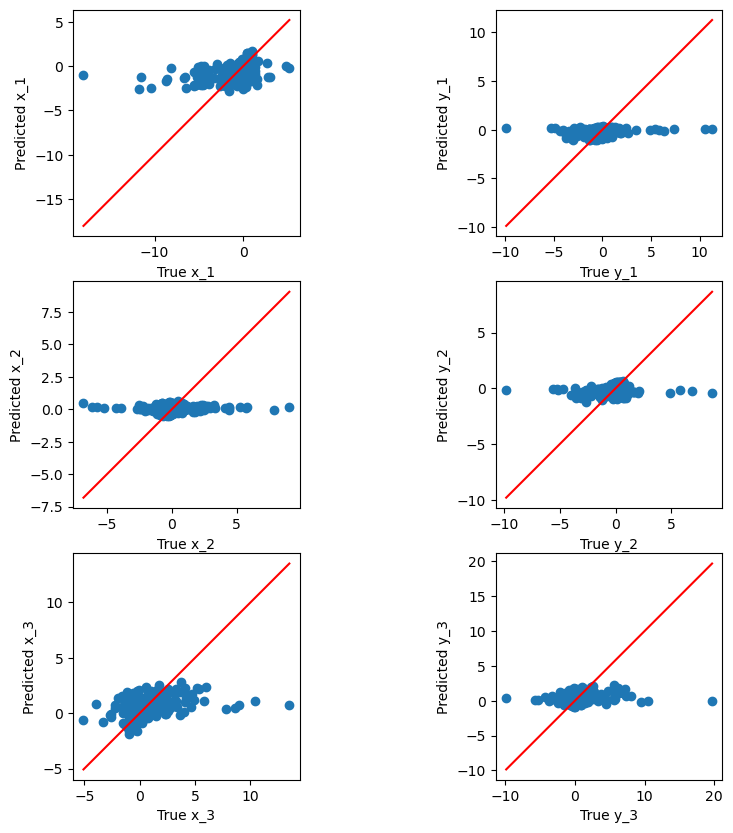

Test RMSE: 1.4415447440559497


In [109]:
y_test_pred = linear_reg.predict(X_test)
y_test_pred_positions = y_test_pred[:, range(6)]

plot_y_yhat(y_test_positions, y_test_pred_positions, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_test_positions, y_test_pred_positions)

print(f"Test RMSE: {rmse}")

### Adding angle between the points to the features

Pre-processing the data

In [110]:
X_chunks, y_chunks = create_features_and_targets(subframes, enable_euclidian_dist=True, enable_angles=True)

In [111]:
X_train, X_dev, y_train, y_dev = train_test_split(X_chunks, y_chunks, test_size=0.2, random_state=42)
X_dev, X_test, y_dev, y_test = train_test_split(X_dev, y_dev, test_size=0.5, random_state=42)

# Concatenate the list of DataFrames into single DataFrames for X and y
X_train = pd.concat(X_train, axis=0)
y_train = pd.concat(y_train, axis=0)
X_dev = pd.concat(X_dev, axis=0)
y_dev = pd.concat(y_dev, axis=0)
X_test = pd.concat(X_test, axis=0)
y_test = pd.concat(y_test, axis=0)

Trying it out on the baseline

In [112]:
linear_reg=make_pipeline(StandardScaler(),
                      LinearRegression())

linear_reg.fit(X_train, y_train)

y_dev_pred = linear_reg.predict(X_dev)

In [113]:
position_columns = ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']

y_dev_positions = y_dev[position_columns].values
y_pred_positions = y_dev_pred[:, range(6)]
y_test_positions = y_test[position_columns].values

Plot y-y hat and RMSE on validation set

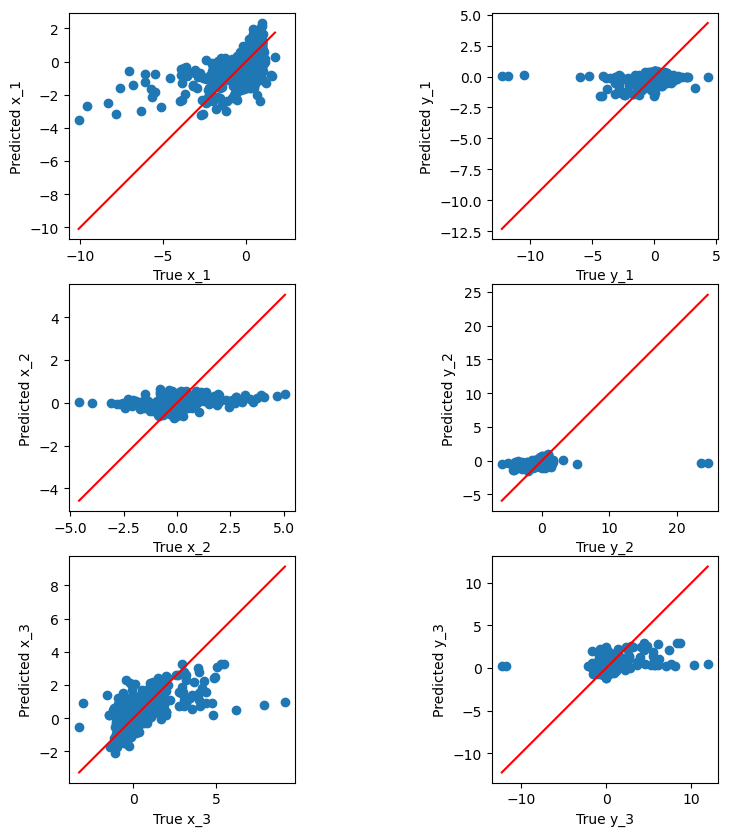

Validation RMSE: 1.3433694736190827


In [114]:
plot_y_yhat(y_dev_positions, y_pred_positions, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_dev_positions, y_pred_positions)

print(f"Validation RMSE: {rmse}")

Plot y-y hat and RMSE on the test set

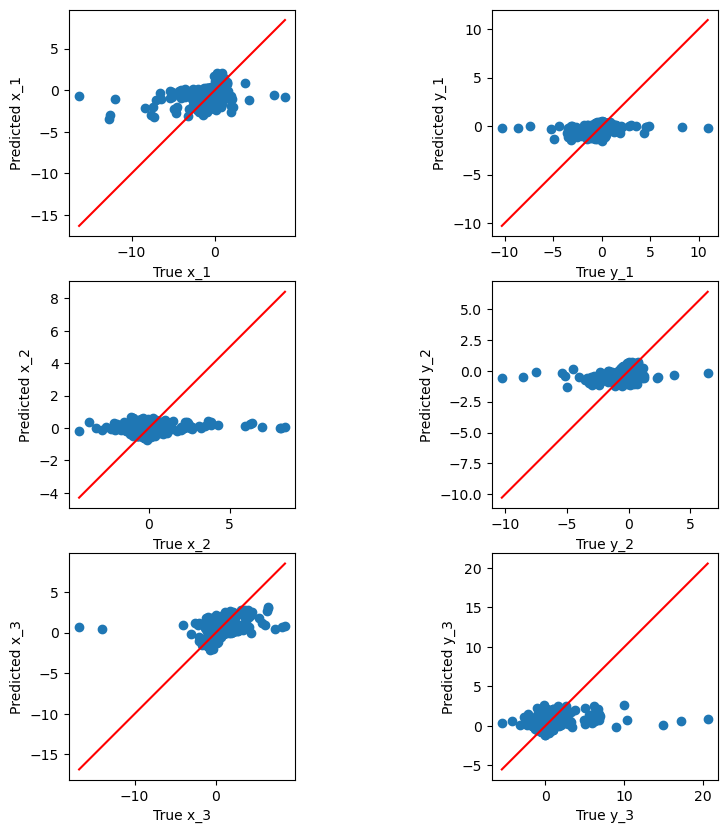

Test RMSE: 1.4302591237255624


In [115]:
y_test_pred = linear_reg.predict(X_test)
y_test_pred_positions = y_test_pred[:, range(6)]

plot_y_yhat(y_test_positions, y_test_pred_positions, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_test_positions, y_test_pred_positions)

print(f"Test RMSE: {rmse}")

### Adding polar coordinates to the features

Pre-processing the data

In [116]:
X_chunks, y_chunks = create_features_and_targets(subframes, enable_euclidian_dist=True, enable_angles=True, enable_polars=True)

In [117]:
X_train, X_dev, y_train, y_dev = train_test_split(X_chunks, y_chunks, test_size=0.2, random_state=42)
X_dev, X_test, y_dev, y_test = train_test_split(X_dev, y_dev, test_size=0.5, random_state=42)

# Concatenate the list of DataFrames into single DataFrames for X and y
X_train = pd.concat(X_train, axis=0)
y_train = pd.concat(y_train, axis=0)
X_dev = pd.concat(X_dev, axis=0)
y_dev = pd.concat(y_dev, axis=0)
X_test = pd.concat(X_test, axis=0)
y_test = pd.concat(y_test, axis=0)

Trying it out on the baseline

In [118]:
linear_reg=make_pipeline(StandardScaler(),
                      LinearRegression())

linear_reg.fit(X_train, y_train)

y_dev_pred = linear_reg.predict(X_dev)

In [119]:
position_columns = ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']

y_dev_positions = y_dev[position_columns].values
y_pred_positions = y_dev_pred[:, range(6)]
y_test_positions = y_test[position_columns].values

Plot y-y hat and RMSE on validation set

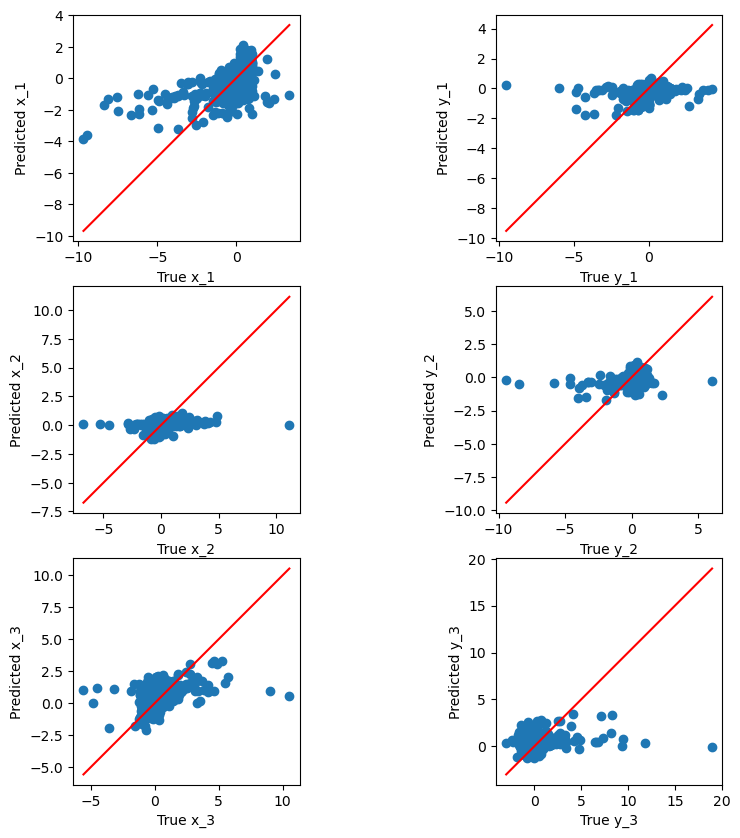

Validation RMSE: 1.33180821643741


In [120]:
plot_y_yhat(y_dev_positions, y_pred_positions, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_dev_positions, y_pred_positions)

print(f"Validation RMSE: {rmse}")

Plot y-y hat and RMSE on the test set

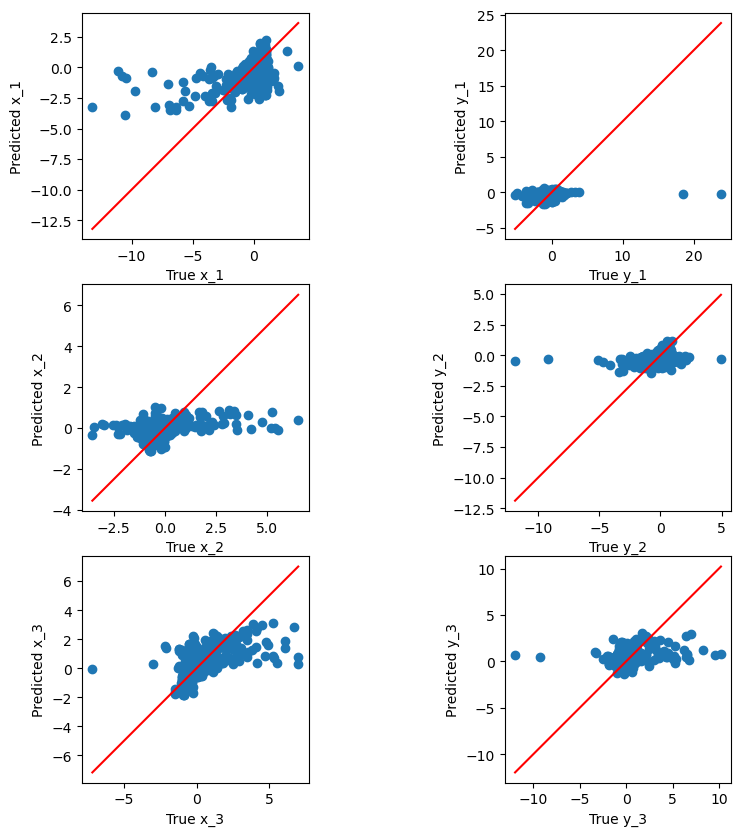

Test RMSE: 1.4066463298162788


In [121]:
y_test_pred = linear_reg.predict(X_test)
y_test_pred_positions = y_test_pred[:, range(6)]

plot_y_yhat(y_test_positions, y_test_pred_positions, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_test_positions, y_test_pred_positions)

print(f"Test RMSE: {rmse}")

### With added features of euclidian distance, angles, polar coordinates. Without y_3 and x_1

Pre-processing the data

In [122]:
X_chunks, y_chunks = create_features_and_targets(subframes, features_to_drop=['x_1', 'y_3'], enable_euclidian_dist=True, enable_angles=True, enable_polars=True)

In [123]:
X_train, X_dev, y_train, y_dev = train_test_split(X_chunks, y_chunks, test_size=0.2, random_state=42)
X_dev, X_test, y_dev, y_test = train_test_split(X_dev, y_dev, test_size=0.5, random_state=42)

# Concatenate the list of DataFrames into single DataFrames for X and y
X_train = pd.concat(X_train, axis=0)
y_train = pd.concat(y_train, axis=0)
X_dev = pd.concat(X_dev, axis=0)
y_dev = pd.concat(y_dev, axis=0)
X_test = pd.concat(X_test, axis=0)
y_test = pd.concat(y_test, axis=0)

Trying it out on the baseline

In [124]:
linear_reg=make_pipeline(StandardScaler(),
                      LinearRegression())

linear_reg.fit(X_train, y_train)

y_dev_pred = linear_reg.predict(X_dev)

In [125]:
position_columns = ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']

y_dev_positions = y_dev[position_columns].values
y_pred_positions = y_dev_pred[:, range(6)]
y_test_positions = y_test[position_columns].values

Plot y-y hat and RMSE on validation set

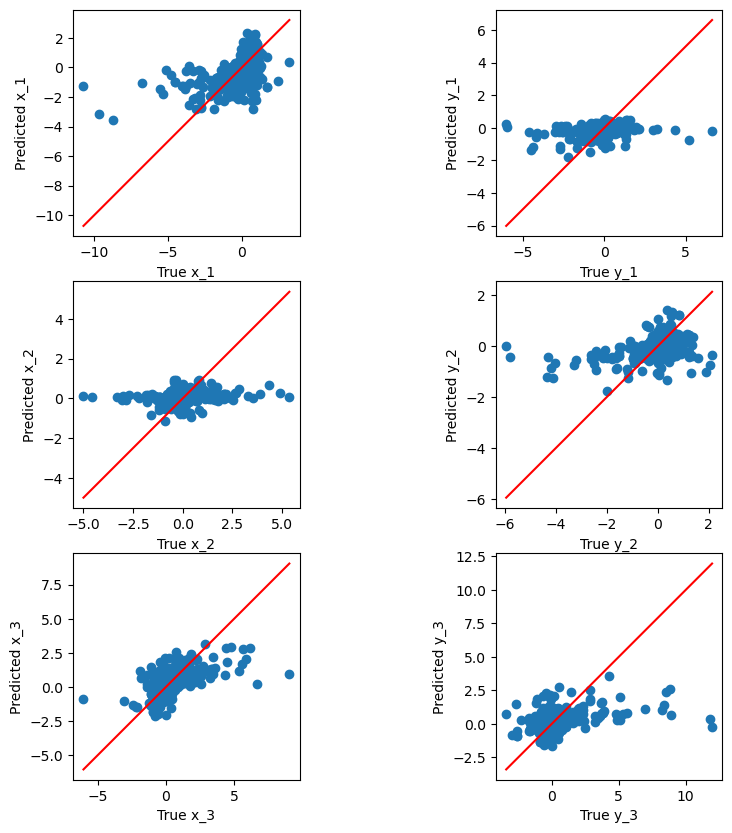

Validation RMSE: 1.3318126370583252


In [126]:
plot_y_yhat(y_dev_positions, y_pred_positions, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_dev_positions, y_pred_positions)

print(f"Validation RMSE: {rmse}")

Plot y-y hat and RMSE on the test set

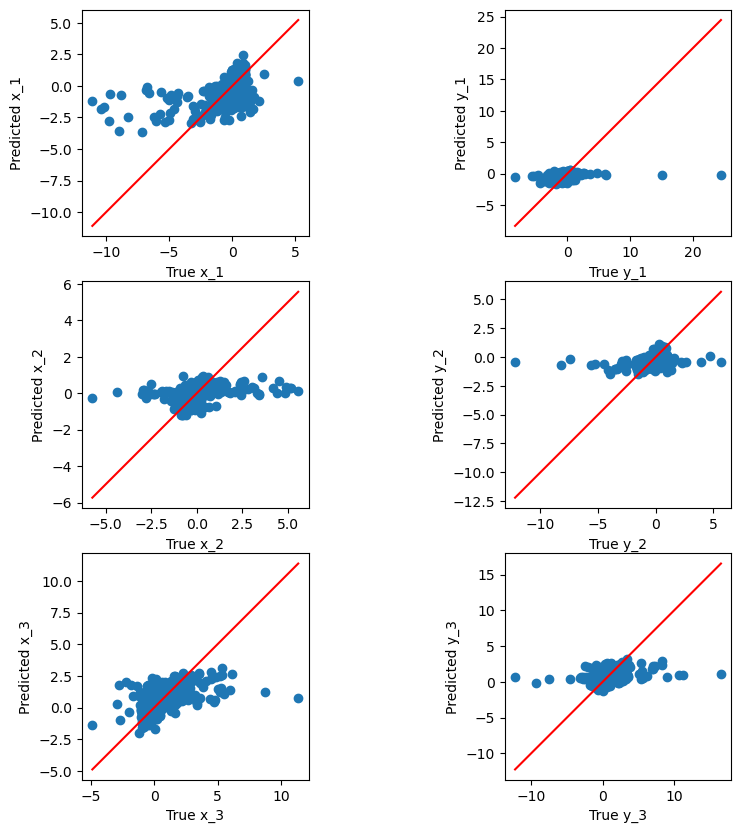

Test RMSE: 1.406658427413449


In [127]:
y_test_pred = linear_reg.predict(X_test)
y_test_pred_positions = y_test_pred[:, range(6)]

plot_y_yhat(y_test_positions, y_test_pred_positions, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_test_positions, y_test_pred_positions)

print(f"Test RMSE: {rmse}")

## Task 3.4 Evaluation of Variable Augmentation

Pre-processing the data

In [128]:
X_chunks, y_chunks = create_features_and_targets(subframes, features_to_drop=['x_1', 'y_3'], enable_euclidian_dist=True, enable_angles=True, enable_polars=True)

In [129]:
X_train, X_dev, y_train, y_dev = train_test_split(X_chunks, y_chunks, test_size=0.2, random_state=42)
X_dev, X_test, y_dev, y_test = train_test_split(X_dev, y_dev, test_size=0.5, random_state=42)

# Concatenate the list of DataFrames into single DataFrames for X and y
X_train = pd.concat(X_train, axis=0)
y_train = pd.concat(y_train, axis=0)
X_dev = pd.concat(X_dev, axis=0)
y_dev = pd.concat(y_dev, axis=0)
X_test = pd.concat(X_test, axis=0)
y_test = pd.concat(y_test, axis=0)

#### Histogram to choose best degree for augmentation

Degree 1: 17 features | RMSE: 1.5603896810626527
Degree 2: 170 features | RMSE: 1.4958040913291262
Degree 3: 1139 features | RMSE: 1.4588487987901035
Degree 4: 5984 features | RMSE: 1.4451102434838292
Best Degree: 4, RMSE: 1.4451102434838292
Degree 1: 17 features | RMSE: 1.5563294649756874
Degree 2: 170 features | RMSE: 1.4909143120992026
Degree 3: 1139 features | RMSE: 1.4509120957806099
Degree 4: 5984 features | RMSE: 1.422657116877368
Best Degree: 4, RMSE: 1.422657116877368
Degree 1: 17 features | RMSE: 1.555383079996615
Degree 2: 170 features | RMSE: 1.4873771527311848
Degree 3: 1139 features | RMSE: 1.4487622915489948
Degree 4: 5984 features | RMSE: 1.4380583066508772
Best Degree: 4, RMSE: 1.4380583066508772
Degree 1: 17 features | RMSE: 1.559134636987642
Degree 2: 170 features | RMSE: 1.4920156669079316
Degree 3: 1139 features | RMSE: 1.448416335994686
Degree 4: 5984 features | RMSE: 1.4219714716194172
Best Degree: 4, RMSE: 1.4219714716194172
Degree 1: 17 features | RMSE: 1.55802

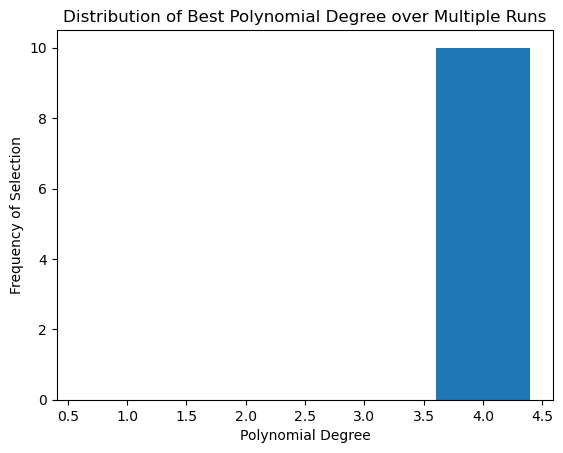

In [130]:
degree_distribution_histogram(X_train, y_train, X_dev, y_dev, regressor=RidgeCV(), degrees=range(1,5))

#### Best degree is 4, but the hardware is unable to run it due to memory limitations.
Using degree 3 instead.

In [131]:
degree = 3

augmented_polyreg=make_pipeline(StandardScaler(), PolynomialFeatures(degree, include_bias=False),
                      RidgeCV())

# Fit the model
augmented_polyreg.fit(X_train, y_train)

# Predict the targets for the validation set
y_dev_pred = augmented_polyreg.predict(X_dev)

In [132]:
position_columns = ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']

y_dev_positions = y_dev[position_columns].values
y_pred_positions = y_dev_pred[:, range(6)]
y_test_positions = y_test[position_columns].values

Plot y-y hat and RMSE in the validation set

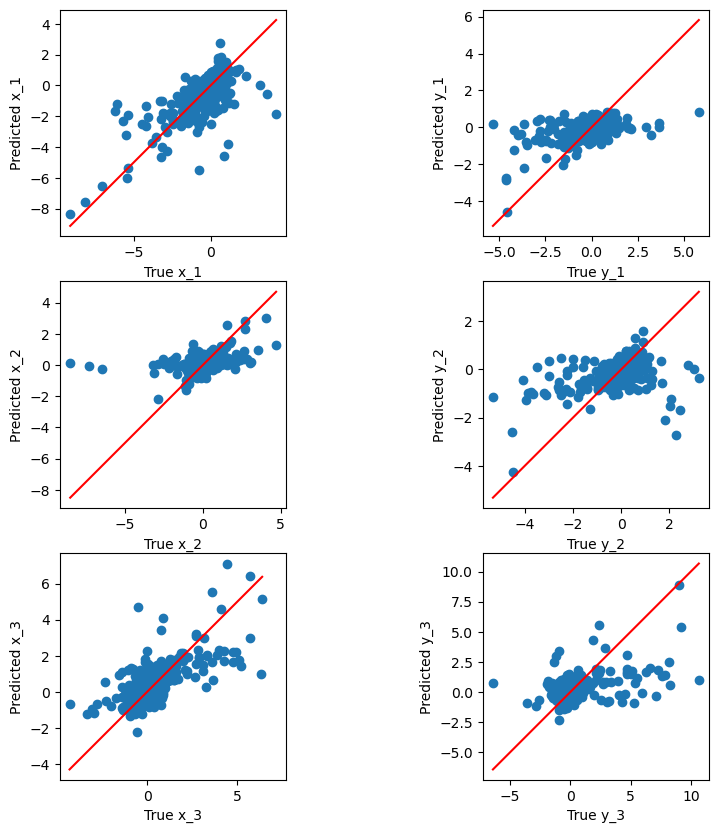

Validation RMSE: 1.2242282106565119


In [133]:
plot_y_yhat(y_dev_positions, y_pred_positions, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_dev_positions, y_pred_positions)

print(f"Validation RMSE: {rmse}")

Plot y-y hat and RMSE in the test set

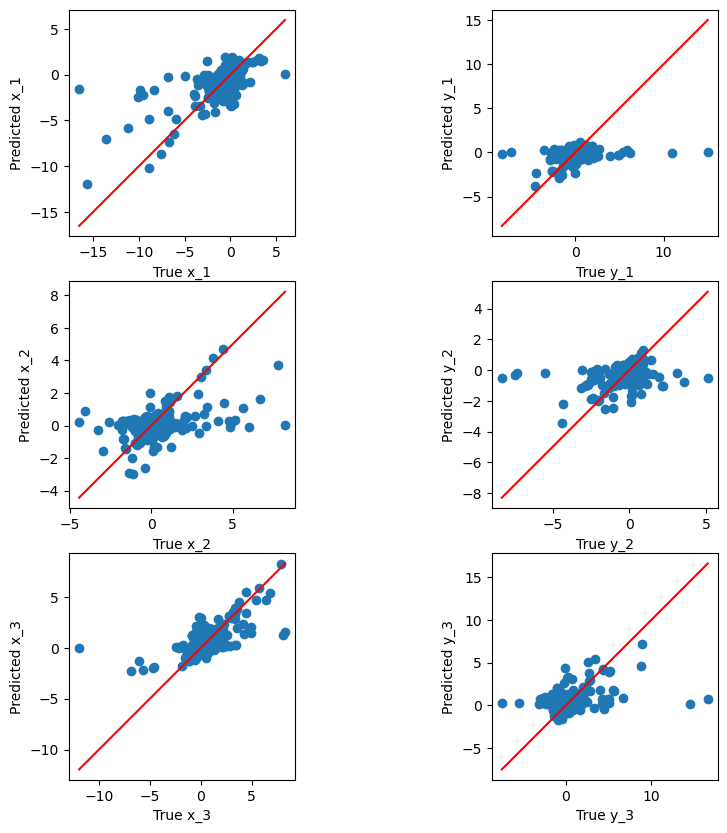

Test RMSE: 1.2792770971731062


In [134]:
y_test_pred = augmented_polyreg.predict(X_test)
y_test_pred_positions = y_test_pred[:, range(6)]

plot_y_yhat(y_test_positions, y_test_pred_positions, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_test_positions, y_test_pred_positions)

print(f"Test RMSE: {rmse}")

Save predictions

In [135]:
X_kaggle_df_augmented = pd.read_csv('../mlNOVA/X_test.csv')
X_kaggle_df_augmented.drop(columns=['Id'], inplace=True)

X_kaggle_df_augmented = augment_dataset(X_kaggle_df_augmented, features_to_drop=['x_1', 'y_3'], enable_euclidian_dist=True, enable_angles=True, enable_polars=True)

In [136]:
y_augmented_polynomial_pred = augmented_polyreg.predict(X_kaggle_df_augmented)

In [137]:
targets = ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3', 'dist_12', 'dist_23', 'dist_13', 'angle_1', 'angle_2', 'angle_3', 'r_1', 'theta_1', 'r_2', 'theta_2', 'r_3', 'theta_3']
save_predictions(y_augmented_polynomial_pred, '../submissions/augmented_polynomial_submission.csv', targets)

C:\Users\rasvi\AppData\Local\Temp\ipykernel_22084\2147481329.py:153: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_positions['Id'] = df_positions.index


Save the model

In [138]:
save_model(augmented_polyreg, "augmented_polynomial-model.onnx", X_kaggle_df_augmented)

<class 'sklearn.pipeline.Pipeline'>
